# Knowledge Graphs for Beginners

A **knowledge graph** is just facts written as connections:

`Amina --enrolled_in--> Python`

- **Node** = a thing (Amina, Python)
- **Edge** = how two things relate (enrolled_in)
- One fact = one **triple**: *(subject, relationship, object)*

No database needed. We use plain Python lists and a small library called NetworkX.

In [2]:
%pip install -q networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. Write the facts
Each line is one triple. Add or change lines and re-run!

In [23]:
triples = [
    ("Amina",   "enrolled_in", "Python"),
    ("Amina",   "enrolled_in", "Data Science"),
    ("Amina",   "enrolled_in", "AI"),
    ("Amina",   "enrolled_in", "Ktor"),
    # ("Brian",   "enrolled_in", "Python"),
    # ("Brian",   "enrolled_in", "ReactJS"),
    # ("Brian",   "enrolled_in", "AI"),
    # ("Brian",   "enrolled_in", "Kotlin"),
    # ("Cynthia", "enrolled_in", "Kotlin"),
    # ("Cynthia", "enrolled_in", "Data Science"),
    # ("Cynthia", "enrolled_in", "ReactJS"),
    ("Python",       "teaches", "Pandas"),
    ("Data Science", "teaches", "Pandas"),
    ("Data Science", "teaches", "AI"),
    ("AI", "teaches", "Deep Learning"),
    ("Data Science", "teaches", "SQL"),
    ("Kotlin",       "teaches", "Android"),
    ("Kotlin",       "teaches", "Spring Boot"),
    ("Spring Boot",       "teaches", "Backend"),
    ("Ling Yu",       "teaches", "Backend"),
    ("Ling Yu",       "teaches", "ReactJS"),
    ("Kotlin",       "teaches", "Data Science"),
    ("Kotlin",       "teaches", "Ktor"),
    ("Ktor",       "teaches", "Network Calls"),
]

In [54]:
#   "from", "School of Life(SoL)"),
# "students of School of Life(SSoL)"
data = [
    # where they come from 
    ("John",   "from", "(SoL)"),
    ("Mary",     "from", "(SoL)"),
    ("Martha",    "from", "(SoL)"),
    ("Amina",    "from", "(SoL)"),
    ("Junior",     "from", "(SoL)"),
    ("Rupert",     "from", "(SoL)"),
    #  where they come from
    ("Brian",    "from", "(sSoL)"),
    ("Joshua",    "from", "(sSoL)"),
    ("Hilbert",   "from", "(sSoL)"),
    ("Harry",    "from", "(sSoL)"),
    ("Porter",    "from", "(sSoL)"),
    ("Parker",    "from", "(sSoL)"),
    #  what they learn
    ("Brian",   "learns", "Mathematics"),
    ("Joshua",   "learns", "Data Science"),
    ("Hilbert",   "learns", "Data Analysis"),
    ("Harry",   "learns", "AI"),
    ("Porter",   "learns", "Software Engineering"),  
    ("Parker",   "learns", "Databases"),   
    #  what they teach
    ("John",   "teaches", "Mathematics"),
    ("Mary",   "teaches", "Data Science"),
    ("Rupert",   "teaches", "Data Analysis"),
    ("Martha",   "teaches", "AI"),
    ("Amina",   "teaches", "Software Engineering"),  
    ("Junior",   "teaches", "Databases"),   
    #  core course outcome
    ("Mathematics",   "focuses on", "Calculus"),
    ("Data Analysis",   "focuses on", "Stats in Data"),
    ("Data Science",   "focuses on", "Data products"),
    ("AI",   "focuses on", "Machine intelligence"),
    ("Software Engineering",   "focuses on", "Software products"),  
    ("Databases",   "focuses on", "Data Storage"),    
]

## 2. Turn the facts into a graph and draw it

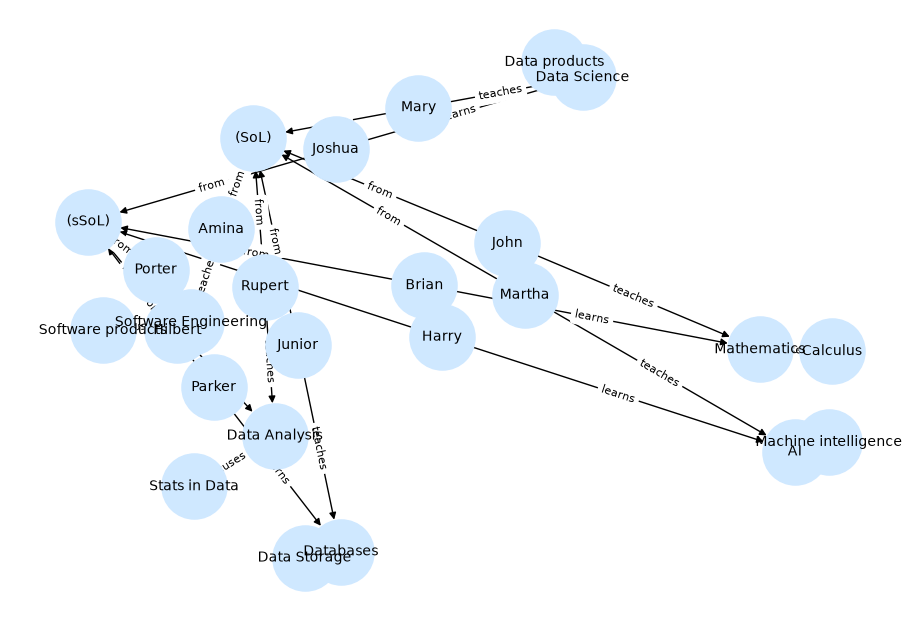

In [55]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
for subject, relation, obj in data:
    G.add_edge(subject, obj, label=relation)

pos = nx.spring_layout(G, seed=3)
plt.figure(figsize=(9, 6))
nx.draw(G, pos, with_labels=True, node_color="#cfe8ff",
        node_size=2200, font_size=10, arrows=True)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=8)
plt.show()
# {'John', 'Junior', 'Martha', 'Mary', 'Porter', 'Rupert'}

## 3. Ask questions
This is the real power: we can follow the connections.

**Q1. What is Amina enrolled in?**

In [45]:
list(G.successors("Amina"))

['(SoL)', 'Software Engineering']

In [46]:
list(G.successors("Parker"))

['(sSoL)', 'Databases']

In [47]:
list(G.successors("Harry"))

['(sSoL)', 'AI']

In [48]:
list(G.successors("Rupert"))

['(SoL)', 'Data Analysis']

**Q2. Who is enrolled in Python?**

In [50]:
list(G.predecessors("Data Storage"))

['Databases']

**Q3. Who shares a course with Amina?** (follow two links)

In [51]:
classmates = set()
for course in G.successors("Amina"):
    for person in G.predecessors(course):
        if person != "Amina":
            classmates.add(person)
classmates

{'John', 'Junior', 'Martha', 'Mary', 'Porter', 'Rupert'}

**Q4. Which skills does Amina learn?** (follow two links forward)

In [25]:
skills = set()
for course in G.successors("Amina"):
    skills.update(G.successors(course))
skills

{'AI', 'Deep Learning', 'Network Calls', 'Pandas', 'SQL'}

In [19]:
triples

[('Amina', 'enrolled_in', 'Python'),
 ('Amina', 'enrolled_in', 'Data Science'),
 ('Amina', 'enrolled_in', 'AI'),
 ('Amina', 'enrolled_in', 'Ktor'),
 ('Brian', 'enrolled_in', 'Python'),
 ('Brian', 'enrolled_in', 'ReactJS'),
 ('Brian', 'enrolled_in', 'AI'),
 ('Brian', 'enrolled_in', 'Kotlin'),
 ('Cynthia', 'enrolled_in', 'Kotlin'),
 ('Cynthia', 'enrolled_in', 'Data Science'),
 ('Cynthia', 'enrolled_in', 'ReactJS'),
 ('Python', 'teaches', 'Pandas'),
 ('Data Science', 'teaches', 'Pandas'),
 ('Data Science', 'teaches', 'AI'),
 ('Data Science', 'teaches', 'SQL'),
 ('Kotlin', 'teaches', 'Android'),
 ('Kotlin', 'teaches', 'Spring Boot'),
 ('Spring Boot', 'teaches', 'Backend'),
 ('Ling Yu', 'teaches', 'Backend'),
 ('Ling Yu', 'teaches', 'ReactJS'),
 ('Kotlin', 'teaches', 'Data Science'),
 ('Kotlin', 'teaches', 'Ktor'),
 ('Ktor', 'teaches', 'Network Calls')]

**Q5. How are Brian and Cynthia connected?**

In [26]:
nx.shortest_path(G.to_undirected(), "Brian", "Cynthia")

NodeNotFound: Source Brian is not in G

## Your turn
1. Add a new student **Daniel** enrolled in **Kotlin** (add one triple, re-run everything).
2. Write code to find *who learns Android*.
3. Add a new kind of fact, e.g. `("Mr Otieno", "teaches_course", "Python")`.

**Why this matters for AI:** in GraphRAG, an LLM reads documents and writes these triples for us. Then we answer questions by following connections, like we just did.